# Phase 2 — Sperm Whale Coda Communication Analysis

## Research question

Can acoustic structure and sequential response patterns in sperm whale codas reveal non-random organization in cross-speaker communication?

## Main idea

This study examines:
- whether coda types can be distinguished from rhythmic and temporal features;
- whether sperm whales show structured turn-taking;
- whether the type of one whale's coda is associated with the type produced next by another whale.

## 1. Setup and Data Loading

Two datasets are used in this analysis:

- **DominicaCodas.csv** — labeled sperm whale codas used to study acoustic structure and train coda-type classification models.
- **sperm-whale-dialogues.csv** — sequential coda events from sperm whale interactions, used to analyze turn-taking and cross-speaker response patterns.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    mutual_info_score
)

In [3]:
# Load datasets

codas = pd.read_csv("data/DominicaCodas.csv")
dialogues = pd.read_csv("data/sperm-whale-dialogues.csv")

print("DominicaCodas shape:", codas.shape)
print("Dialogue dataset shape:", dialogues.shape)

DominicaCodas shape: (8719, 18)
Dialogue dataset shape: (3840, 33)


## 2. Data Preparation

The labeled coda dataset was restricted to the EC1 clan to reduce variation associated with different cultural vocal repertoires. Entries labeled as noise were removed before analysis.

The main acoustic analysis focuses on four selected 5-click coda types: **1+1+3, 2+3, 5R1, and 5R2**. Restricting the comparison to codas with the same number of clicks allows their rhythmic structures to be compared using the same four inter-click intervals.

In [4]:
# Clean labeled coda dataset

clean_codas = codas[
    (codas["Clan"] == "EC1")
    &
    (~codas["CodaType"].astype(str).str.contains("NOISE", case=False))
].copy()

print("Original dataset:", codas.shape)
print("Clean dataset:", clean_codas.shape)
print("Number of coda types:", clean_codas["CodaType"].nunique())

Original dataset: (8719, 18)
Clean dataset: (7268, 18)
Number of coda types: 24


In [5]:
# Select the four 5-click coda types used in the main analysis

five_click_types = ["1+1+3", "2+3", "5R1", "5R2"]

five_click_df = clean_codas[
    clean_codas["CodaType"].isin(five_click_types)
].copy()

print("5-click dataset shape:", five_click_df.shape)

print("\nSamples per coda type:")
print(
    five_click_df["CodaType"]
    .value_counts()
    .reindex(five_click_types)
)

5-click dataset shape: (5448, 18)

Samples per coda type:
CodaType
1+1+3    3574
2+3        77
5R1      1510
5R2       287
Name: count, dtype: int64


In [6]:
# Normalize inter-click intervals to describe rhythm independently of tempo

ici_columns = ["ICI1", "ICI2", "ICI3", "ICI4"]

ici_sum = five_click_df[ici_columns].sum(axis=1)

for col in ici_columns:
    five_click_df[f"norm_{col}"] = (
        five_click_df[col] / ici_sum
    )

five_click_df[
    [
        "CodaType",
        "Duration",
        "norm_ICI1",
        "norm_ICI2",
        "norm_ICI3",
        "norm_ICI4"
    ]
].head()

,CodaType,Duration,norm_ICI1,norm_ICI2,norm_ICI3,norm_ICI4
11,5R1,0.339,0.265487,0.227139,0.224189,0.283186
12,5R1,0.295,0.210169,0.284746,0.213559,0.291525
13,5R1,0.270,0.229630,0.233333,0.229630,0.307407
39,5R1,0.326,0.297546,0.217791,0.233129,0.251534
54,1+1+3,0.860,0.334884,0.304651,0.197674,0.162791


## 3. Rhythmic and Tempo Structure

To compare 5-click codas, each coda was represented using four normalized inter-click intervals (ICIs) and its total duration.

The normalized ICIs describe the **relative rhythmic pattern** within a coda, while total duration captures its **overall tempo**. Separating rhythm from tempo allows codas with similar internal timing patterns but different production speeds to be distinguished.

In [7]:
duration_summary = (
    five_click_df
    .groupby("CodaType")["Duration"]
    .agg(["count", "mean", "std", "median", "min", "max"])
    .reindex(five_click_types)
)

duration_summary.round(3)

,count,mean,std,median,min,max
CodaType,,,,,,
1+1+3,3574,1.073,0.219,1.090,0.645,1.635
2+3,77,0.655,0.030,0.652,0.571,0.732
5R1,1510,0.330,0.021,0.329,0.232,0.429
5R2,287,0.510,0.032,0.508,0.417,0.598


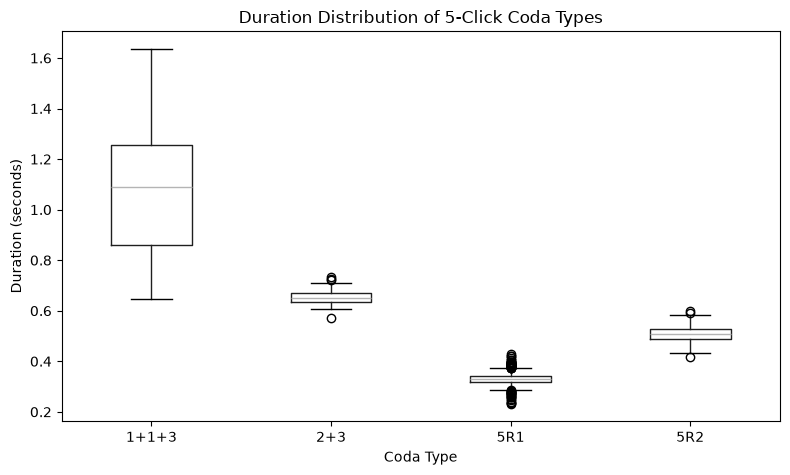

In [47]:
fig, ax = plt.subplots(figsize=(8, 5))

five_click_df.boxplot(
    column="Duration",
    by="CodaType",
    grid=False,
    ax=ax
)

ax.set_title("Duration Distribution of 5-Click Coda Types")
plt.suptitle("")
ax.set_xlabel("Coda Type")
ax.set_ylabel("Duration (seconds)")
plt.tight_layout()


fig.savefig(
    "figure1_duration_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [9]:
rhythm_cols = [
    "norm_ICI1",
    "norm_ICI2",
    "norm_ICI3",
    "norm_ICI4"
]

rhythm_means = (
    five_click_df
    .groupby("CodaType")[rhythm_cols]
    .mean()
    .reindex(five_click_types)
)

rhythm_means.round(3)

,norm_ICI1,norm_ICI2,norm_ICI3,norm_ICI4
CodaType,,,,
1+1+3,0.337,0.326,0.174,0.162
2+3,0.079,0.318,0.299,0.304
5R1,0.286,0.279,0.225,0.211
5R2,0.240,0.260,0.240,0.260


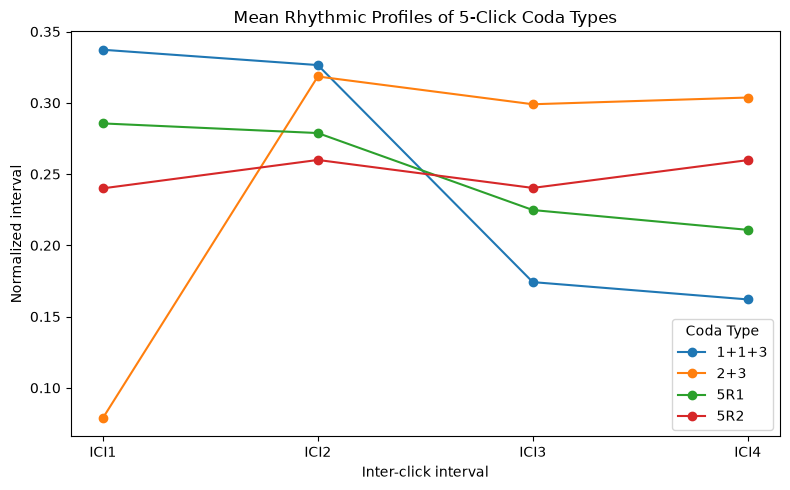

In [48]:
plt.figure(figsize=(8, 5))

x = [1, 2, 3, 4]

for coda_type in five_click_types:
    plt.plot(
        x,
        rhythm_means.loc[coda_type],
        marker="o",
        label=coda_type
    )

plt.xticks(x, ["ICI1", "ICI2", "ICI3", "ICI4"])
plt.xlabel("Inter-click interval")
plt.ylabel("Normalized interval")
plt.title("Mean Rhythmic Profiles of 5-Click Coda Types")
plt.legend(title="Coda Type")
plt.tight_layout()

plt.savefig(
    "figure2_rhythmic_profiles.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

### Interpretation

The four selected 5-click coda types differed in both rhythmic structure and overall duration.

The normalized inter-click interval profiles showed that some coda types had clearly different internal timing patterns. The 5R1 and 5R2 codas were more similar in rhythmic structure than some of the other types, but differed substantially in total duration.

This suggests that both rhythm and tempo contain useful information for distinguishing coda categories. The next analysis tests whether these acoustic patterns form natural groups without using the known coda labels.

## 4. Unsupervised Clustering

To test whether the selected coda types form natural acoustic groups, K-means clustering was applied without using the known coda labels.

Because the four coda types are strongly imbalanced in the dataset, the clustering analysis used balanced samples with the same number of examples from each coda type.

Three feature representations were compared:

1. **Rhythm only** — normalized inter-click intervals.
2. **Tempo only** — total coda duration.
3. **Rhythm + tempo** — normalized inter-click intervals together with duration.

Clustering quality was evaluated using the silhouette score, while agreement with known coda labels was evaluated using Adjusted Rand Index (ARI) and Normalized Mutual Information (NMI).

In [11]:
# Create a balanced dataset using the smallest class size

min_class_size = five_click_df["CodaType"].value_counts().min()

balanced_df = (
    five_click_df
    .groupby("CodaType", group_keys=False)
    .sample(n=min_class_size, random_state=42)
    .reset_index(drop=True)
)

print("Balanced dataset shape:", balanced_df.shape)
print("\nSamples per type:")
print(balanced_df["CodaType"].value_counts())

Balanced dataset shape: (308, 22)

Samples per type:
CodaType
1+1+3    77
2+3      77
5R1      77
5R2      77
Name: count, dtype: int64


In [12]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)

feature_sets = {
    "Rhythm only": ["norm_ICI1", "norm_ICI2", "norm_ICI3", "norm_ICI4"],
    "Tempo only": ["Duration"],
    "Rhythm + Tempo": [
        "norm_ICI1",
        "norm_ICI2",
        "norm_ICI3",
        "norm_ICI4",
        "Duration"
    ]
}

results = []

for seed in range(50):

    balanced_sample = (
        five_click_df
        .groupby("CodaType", group_keys=False)
        .sample(n=min_class_size, random_state=seed)
        .reset_index(drop=True)
    )

    y_true = balanced_sample["CodaType"]

    for feature_name, cols in feature_sets.items():

        X = balanced_sample[cols].values
        X_scaled = StandardScaler().fit_transform(X)

        for k in range(2, 7):

            model = KMeans(
                n_clusters=k,
                random_state=seed,
                n_init=20
            )

            labels = model.fit_predict(X_scaled)

            results.append({
                "seed": seed,
                "features": feature_name,
                "k": k,
                "silhouette": silhouette_score(X_scaled, labels),
                "ARI": adjusted_rand_score(y_true, labels),
                "NMI": normalized_mutual_info_score(y_true, labels)
            })

clustering_results = pd.DataFrame(results)

clustering_results.head()

,seed,features,k,silhouette,ARI,NMI
0,0,Rhythm only,2,0.509941,0.325390,0.536315
1,0,Rhythm only,3,0.548178,0.664543,0.772251
2,0,Rhythm only,4,0.489412,0.783626,0.814320
3,0,Rhythm only,5,0.480927,0.687553,0.766553
4,0,Rhythm only,6,0.428411,0.659962,0.744696


In [13]:
clustering_summary = (
    clustering_results
    .groupby(["features", "k"])[["silhouette", "ARI", "NMI"]]
    .agg(["mean", "std"])
)

clustering_summary.round(3)

silhouette           ARI           NMI       
                       mean    std   mean    std   mean    std
features       k                                              
Rhythm + Tempo 2      0.478  0.014  0.318  0.009  0.544  0.019
               3      0.565  0.011  0.683  0.019  0.818  0.019
               4      0.469  0.012  0.801  0.057  0.823  0.040
               5      0.462  0.013  0.704  0.061  0.774  0.039
               6      0.451  0.013  0.681  0.030  0.784  0.020
Rhythm only    2      0.514  0.007  0.329  0.002  0.562  0.014
               3      0.530  0.013  0.642  0.016  0.748  0.019
               4      0.502  0.020  0.601  0.081  0.718  0.037
               5      0.458  0.014  0.624  0.046  0.716  0.025
               6      0.415  0.015  0.610  0.037  0.707  0.024
Tempo only     2      0.702  0.017  0.203  0.041  0.400  0.049
               3      0.616  0.011  0.513  0.024  0.639  0.024
               4      0.673  0.034  0.717  0.119  0.804  0.072
               5      0.709  0.016  0.817  0.031  0.850  0.020
               6      0.717  0.011  0.837  0.016  0.855  0.016

In [14]:
k4_summary = (
    clustering_results[
        clustering_results["k"] == 4
    ]
    .groupby("features")[["silhouette", "ARI", "NMI"]]
    .mean()
    .round(3)
)

k4_summary

,silhouette,ARI,NMI
features,,,
Rhythm + Tempo,0.469,0.801,0.823
Rhythm only,0.502,0.601,0.718
Tempo only,0.673,0.717,0.804


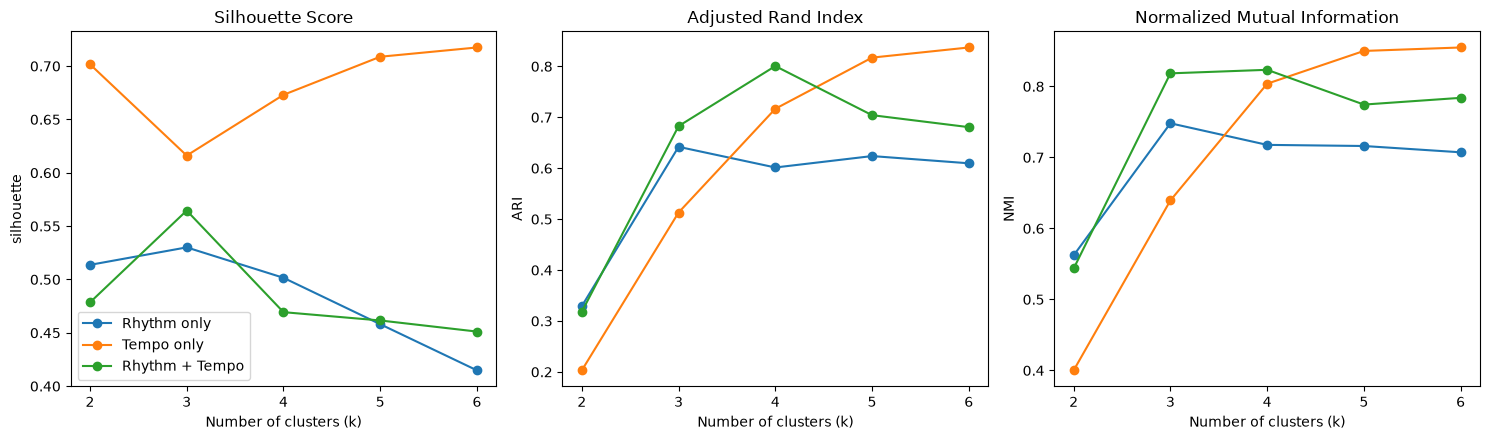

In [49]:
# Mean clustering performance across 50 balanced resamples

plot_data = (
    clustering_results
    .groupby(["features", "k"])[["silhouette", "ARI", "NMI"]]
    .mean()
    .reset_index()
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

metrics = ["silhouette", "ARI", "NMI"]
titles = ["Silhouette Score", "Adjusted Rand Index", "Normalized Mutual Information"]

for ax, metric, title in zip(axes, metrics, titles):
    for feature_name in feature_sets.keys():
        subset = plot_data[plot_data["features"] == feature_name]

        ax.plot(
            subset["k"],
            subset[metric],
            marker="o",
            label=feature_name
        )

    ax.set_title(title)
    ax.set_xlabel("Number of clusters (k)")
    ax.set_ylabel(metric)
    ax.set_xticks(range(2, 7))

axes[0].legend()
plt.tight_layout()

plt.savefig(
    "figure3_clustering_metrics.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

### Interpretation

Repeated clustering across 50 balanced resamples showed that the acoustic feature representation strongly affected the recovered cluster structure.

Using rhythm alone produced moderate agreement with the known coda categories. Tempo alone separated the categories more strongly, while the combined rhythm-and-tempo representation produced the highest agreement with the known four-type labeling at **k = 4** (mean ARI ≈ 0.801; mean NMI ≈ 0.823).

The silhouette score was lower for the combined representation than for tempo alone, indicating that the known four coda categories are not simply four maximally compact geometric clusters.

Overall, these results suggest that both relative rhythm and overall tempo contribute to coda-type structure.

## 5. Coda-Type Classification and Grouped Validation

To test whether the selected coda types can be reliably distinguished from their acoustic features, a supervised classification model was trained using normalized inter-click intervals together with total duration.

Because observations from the same recording context may be more similar to each other than observations from different contexts, model performance was evaluated using grouped cross-validation rather than only a random train-test split.

Each group was defined using the combination of **Date + Unit**, which acts as a proxy for recording context.

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report
)

In [17]:
classification_features = [
    "norm_ICI1",
    "norm_ICI2",
    "norm_ICI3",
    "norm_ICI4",
    "Duration"
]

X = five_click_df[classification_features].copy()
y = five_click_df["CodaType"].copy()

groups = (
    five_click_df["Date"].astype(str)
    + "_"
    + five_click_df["Unit"].astype(str)
)

print("Number of samples:", len(X))
print("Number of groups:", groups.nunique())

print("\nIndependent groups per coda type:")
print(
    five_click_df
    .assign(recording_group=groups)
    .groupby("CodaType")["recording_group"]
    .nunique()
    .reindex(five_click_types)
)

Number of samples: 5448
Number of groups: 97

Independent groups per coda type:
CodaType
1+1+3    75
2+3      11
5R1      77
5R2      27
Name: recording_group, dtype: int64


In [18]:
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_results = []
oof_predictions = pd.Series(index=five_click_df.index, dtype="object")

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X, y, groups),
    start=1
):

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    train_groups = groups.iloc[train_idx]
    test_groups = groups.iloc[test_idx]

    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        )
    )

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    oof_predictions.iloc[test_idx] = y_pred

    overlap = len(
        set(train_groups).intersection(set(test_groups))
    )

    fold_results.append({
        "fold": fold,
        "accuracy": accuracy_score(y_test, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
        "group_overlap": overlap
    })

fold_results = pd.DataFrame(fold_results)

fold_results.round(4)

,fold,accuracy,balanced_accuracy,group_overlap
0,1,0.9916,0.9938,0
1,2,0.9943,0.9960,0
2,3,1.0000,1.0000,0
3,4,0.9972,0.9975,0
4,5,0.9971,0.9984,0


In [19]:
print(
    "Mean accuracy:",
    round(fold_results["accuracy"].mean(), 4)
)

print(
    "Mean balanced accuracy:",
    round(fold_results["balanced_accuracy"].mean(), 4)
)

print(
    "Std balanced accuracy:",
    round(fold_results["balanced_accuracy"].std(), 4)
)

print(
    "\nMaximum group overlap:",
    fold_results["group_overlap"].max()
)

Mean accuracy: 0.996
Mean balanced accuracy: 0.9971
Std balanced accuracy: 0.0024

Maximum group overlap: 0


In [20]:
print(
    classification_report(
        y,
        oof_predictions,
        digits=3
    )
)

              precision    recall  f1-score   support

       1+1+3      1.000     0.998     0.999      3574
         2+3      0.987     1.000     0.994        77
         5R1      1.000     0.991     0.995      1510
         5R2      0.932     1.000     0.965       287

    accuracy                          0.996      5448
   macro avg      0.980     0.997     0.988      5448
weighted avg      0.996     0.996     0.996      5448



### Interpretation

The acoustic feature set consisting of normalized rhythm and total duration distinguished the four selected coda types with very high accuracy.

Five-fold stratified grouped cross-validation achieved a mean balanced accuracy of approximately **0.997**, with no overlap between training and test recording groups.

This indicates that the classification performance was not driven only by repeated observations from the same Date + Unit recording contexts.

However, these results should be interpreted as evidence that the coda categories are acoustically stable and distinguishable, not as evidence that their biological meanings are known.

## 6. Dialogue Timing and Turn-Taking

The dialogue dataset was used to examine the temporal organization of sperm whale exchanges.

For each audio file, coda events were ordered by time. Consecutive events were then classified as either:

- **speaker-change transitions** — the next coda was produced by a different whale;
- **same-speaker transitions** — the next coda was produced by the same whale.

The response gap was defined as the time between the end of the previous coda and the start of the following coda.

In [21]:
# Create audio-file identifiers and order dialogue events in time

dialogue_events = dialogues.copy()

dialogue_events["AudioFile"] = (
    dialogue_events["REC"]
    .astype(str)
    .str.extract(r"(^[^_]+)", expand=False)
)

dialogue_events = (
    dialogue_events
    .sort_values(["AudioFile", "TsTo"])
    .reset_index(drop=True)
)

dialogue_events["prev_whale"] = (
    dialogue_events
    .groupby("AudioFile")["Whale"]
    .shift(1)
)

dialogue_events["prev_time"] = (
    dialogue_events
    .groupby("AudioFile")["TsTo"]
    .shift(1)
)

dialogue_events["prev_duration"] = (
    dialogue_events
    .groupby("AudioFile")["Duration"]
    .shift(1)
)

dialogue_events["response_gap"] = (
    dialogue_events["TsTo"]
    - (
        dialogue_events["prev_time"]
        + dialogue_events["prev_duration"]
    )
)

dialogue_events["speaker_change"] = (
    dialogue_events["prev_whale"].notna()
    &
    (dialogue_events["Whale"] != dialogue_events["prev_whale"])
)

In [22]:
speaker_change_gaps = (
    dialogue_events.loc[
        dialogue_events["speaker_change"] &
        dialogue_events["response_gap"].notna(),
        "response_gap"
    ]
)

same_speaker_gaps = (
    dialogue_events.loc[
        (~dialogue_events["speaker_change"]) &
        dialogue_events["response_gap"].notna(),
        "response_gap"
    ]
)

print("Speaker-change gaps:")
print(speaker_change_gaps.describe())

print("\nSame-speaker gaps:")
print(same_speaker_gaps.describe())

Speaker-change gaps:
count    2317.000000
mean       12.818458
std       128.230984
min        -1.965472
25%        -0.469895
50%         0.728940
75%         2.809626
max      2949.535707
Name: response_gap, dtype: float64

Same-speaker gaps:
count    1475.000000
mean       34.078765
std       299.558014
min         0.301033
25%         2.766446
50%         3.523537
75%         4.514704
max      6523.151065
Name: response_gap, dtype: float64


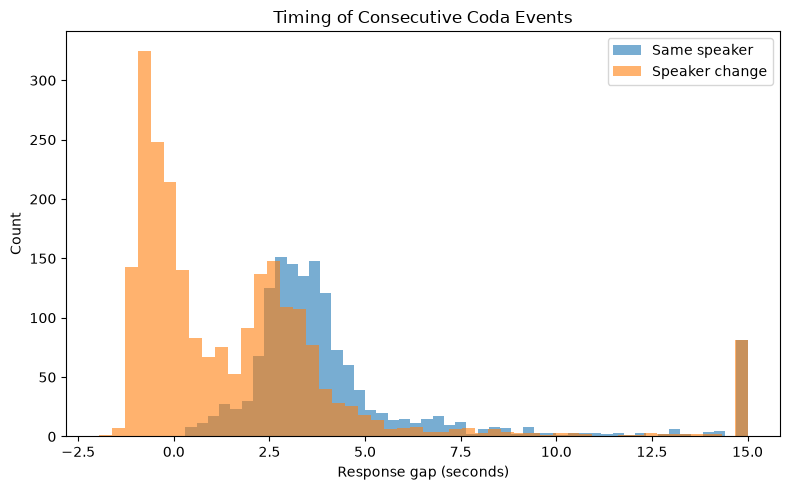

In [50]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    same_speaker_gaps.clip(-2, 15),
    bins=50,
    alpha=0.6,
    label="Same speaker"
)

ax.hist(
    speaker_change_gaps.clip(-2, 15),
    bins=50,
    alpha=0.6,
    label="Speaker change"
)

ax.set_xlabel("Response gap (seconds)")
ax.set_ylabel("Count")
ax.set_title("Timing of Consecutive Coda Events")
ax.legend()

plt.tight_layout()


plt.savefig(
    "figure4_turn_taking_timing.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [24]:
print("Audio files:", dialogue_events["AudioFile"].nunique())
print(
    "Speaker-change transitions:",
    dialogue_events["speaker_change"].sum()
)

Audio files: 48
Speaker-change transitions: 2317


In [25]:
from scipy.stats import wilcoxon

# Median response gaps within each audio file

file_gap_summary = (
    dialogue_events[
        dialogue_events["response_gap"].notna()
    ]
    .assign(
        transition_type=np.where(
            dialogue_events.loc[
                dialogue_events["response_gap"].notna(),
                "speaker_change"
            ],
            "Speaker change",
            "Same speaker"
        )
    )
    .groupby(
        ["AudioFile", "transition_type"]
    )["response_gap"]
    .median()
    .unstack()
    .dropna()
)

print("Audio files with both transition types:", len(file_gap_summary))

file_gap_summary.head()

Audio files with both transition types: 40


transition_type,Same speaker,Speaker change
AudioFile,,
sw061b001,3.254188,0.794508
sw061b002,3.219800,0.526342
sw061b003,2.935246,0.496747
sw061b004,2.968043,1.192805
sw078a001,2.595154,0.381162


In [26]:
from scipy.stats import wilcoxon

file_gap_summary = (
    dialogue_events[
        dialogue_events["response_gap"].notna()
    ]
    .assign(
        transition_type=np.where(
            dialogue_events.loc[
                dialogue_events["response_gap"].notna(),
                "speaker_change"
            ],
            "Speaker change",
            "Same speaker"
        )
    )
    .groupby(
        ["AudioFile", "transition_type"]
    )["response_gap"]
    .median()
    .unstack()
    .dropna()
)

print("Audio files with both transition types:", len(file_gap_summary))
file_gap_summary.head()

Audio files with both transition types: 40


transition_type,Same speaker,Speaker change
AudioFile,,
sw061b001,3.254188,0.794508
sw061b002,3.219800,0.526342
sw061b003,2.935246,0.496747
sw061b004,2.968043,1.192805
sw078a001,2.595154,0.381162


In [27]:
print("Across-file median summary:")
print(
    file_gap_summary[
        ["Speaker change", "Same speaker"]
    ].describe()
)

file_gap_summary["difference"] = (
    file_gap_summary["Same speaker"]
    - file_gap_summary["Speaker change"]
)

print("\nDifference: same speaker - speaker change")
print(file_gap_summary["difference"].describe())

Across-file median summary:
transition_type  Speaker change  Same speaker
count                 40.000000     40.000000
mean                   1.211266      3.605917
std                    0.844250      0.522927
min                   -0.189332      2.497127
25%                    0.616180      3.262619
50%                    1.042096      3.643575
75%                    1.842364      3.935822
max                    3.444109      4.838671

Difference: same speaker - speaker change
count    40.000000
mean      2.394651
std       0.996030
min       0.196708
25%       1.409204
50%       2.577036
75%       3.157498
max       4.048198
Name: difference, dtype: float64


In [28]:
wilcoxon_result = wilcoxon(
    file_gap_summary["Same speaker"],
    file_gap_summary["Speaker change"],
    alternative="greater"
)

print("Wilcoxon statistic:", wilcoxon_result.statistic)
print("p-value:", wilcoxon_result.pvalue)

Wilcoxon statistic: 820.0
p-value: 9.094947017729282e-13


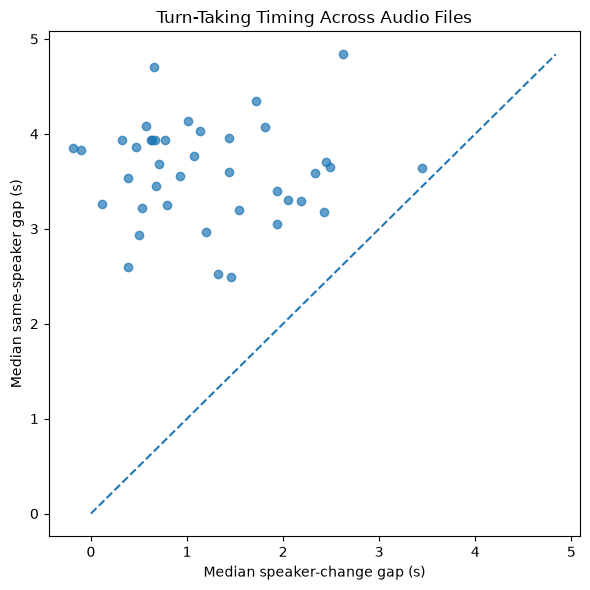

In [29]:
fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(
    file_gap_summary["Speaker change"],
    file_gap_summary["Same speaker"],
    alpha=0.7
)

limit = max(
    file_gap_summary["Speaker change"].max(),
    file_gap_summary["Same speaker"].max()
)

ax.plot(
    [0, limit],
    [0, limit],
    linestyle="--"
)

ax.set_xlabel("Median speaker-change gap (s)")
ax.set_ylabel("Median same-speaker gap (s)")
ax.set_title("Turn-Taking Timing Across Audio Files")

plt.tight_layout()
plt.show()

### Interpretation

Across audio files, speaker-change transitions occurred after substantially shorter gaps than same-speaker continuations.

Among the 40 audio files containing both transition types, the median speaker-change gap was approximately **1.04 s**, compared with approximately **3.64 s** for same-speaker continuations.

The paired difference was positive in every analyzed audio file, and a one-sided Wilcoxon signed-rank test showed a highly significant difference (**W = 820, p ≈ 9.09 × 10⁻13**).

These results provide evidence for structured temporal turn-taking in sperm whale coda exchanges. They do not, by themselves, indicate the semantic content of the exchanged codas.

## 7. Cross-Speaker Coda Response Structure

The next analysis asks whether the type of coda produced by one whale is associated with the type produced next by another whale.

Because the dialogue dataset does not contain the same four coda labels used in the training dataset, the classifier trained on labeled codas was first used to assign acoustic coda types to 5-click dialogue events.

To reduce uncertain assignments, only predictions with high model confidence and acoustic features within the observed training ranges were retained. Other events were labeled as **Unknown**.

In [30]:
final_classifier = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    )
)

final_classifier.fit(
    five_click_df[classification_features],
    five_click_df["CodaType"]
)

print("Final classifier trained on:", len(five_click_df), "labeled codas")

Final classifier trained on: 5448 labeled codas


In [31]:
dialogue_5 = dialogue_events[
    dialogue_events["nClicks"] == 5
].copy()

dialogue_ici_cols = ["ICI1", "ICI2", "ICI3", "ICI4"]

dialogue_ici_sum = dialogue_5[dialogue_ici_cols].sum(axis=1)

for col in dialogue_ici_cols:
    dialogue_5[f"norm_{col}"] = (
        dialogue_5[col] / dialogue_ici_sum
    )

print("5-click dialogue codas:", len(dialogue_5))

5-click dialogue codas: 2949


In [32]:
training_ranges = pd.DataFrame({
    "min": five_click_df[classification_features].min(),
    "max": five_click_df[classification_features].max()
})

dialogue_ranges = pd.DataFrame({
    "min": dialogue_5[classification_features].min(),
    "max": dialogue_5[classification_features].max()
})

print("Training feature ranges:")
display(training_ranges)

print("\nDialogue feature ranges:")
display(dialogue_ranges)

Training feature ranges:


,min,max
norm_ICI1,0.049083,0.426472
norm_ICI2,0.183976,0.401958
norm_ICI3,0.097427,0.391447
norm_ICI4,0.088210,0.379096
Duration,0.232000,1.635384



Dialogue feature ranges:


,min,max
norm_ICI1,0.061320,0.474784
norm_ICI2,0.011370,0.493305
norm_ICI3,0.097427,0.433837
norm_ICI4,0.042512,0.380904
Duration,0.187108,1.688592


In [33]:
within_training_range = pd.Series(
    True,
    index=dialogue_5.index
)

for feature in classification_features:
    within_training_range &= (
        dialogue_5[feature]
        .between(
            training_ranges.loc[feature, "min"],
            training_ranges.loc[feature, "max"]
        )
    )

dialogue_5["within_training_range"] = within_training_range

print(dialogue_5["within_training_range"].value_counts())
print(
    "\nPercent within training ranges:",
    round(
        100 * dialogue_5["within_training_range"].mean(),
        2
    )
)

within_training_range
True     2930
False      19
Name: count, dtype: int64

Percent within training ranges: 99.36


In [34]:
X_dialogue = dialogue_5[classification_features]

dialogue_5["predicted_type"] = (
    final_classifier.predict(X_dialogue)
)

prediction_probabilities = (
    final_classifier.predict_proba(X_dialogue)
)

dialogue_5["confidence"] = (
    prediction_probabilities.max(axis=1)
)

In [35]:
confidence_threshold = 0.95

dialogue_5["assigned_type"] = np.where(
    (dialogue_5["confidence"] >= confidence_threshold)
    &
    dialogue_5["within_training_range"],
    dialogue_5["predicted_type"],
    "Unknown"
)

print("Assigned dialogue coda types:")
print(dialogue_5["assigned_type"].value_counts())

print("\nConfidence summary:")
print(dialogue_5["confidence"].describe())

Assigned dialogue coda types:
assigned_type
1+1+3      2148
5R1         491
Unknown     159
5R2         127
2+3          24
Name: count, dtype: int64

Confidence summary:
count    2949.000000
mean        0.989216
std         0.041896
min         0.512937
25%         0.995758
50%         0.999989
75%         1.000000
max         1.000000
Name: confidence, dtype: float64


In [36]:
outside_range = (
    ~dialogue_5["within_training_range"]
).sum()

low_confidence = (
    dialogue_5["confidence"] < confidence_threshold
).sum()

unknown_total = (
    dialogue_5["assigned_type"] == "Unknown"
).sum()

print("Outside training range:", outside_range)
print("Confidence below 0.95:", low_confidence)
print("Total Unknown:", unknown_total)

Outside training range: 19
Confidence below 0.95: 141
Total Unknown: 159


In [37]:
# Map predicted 5-click labels back to the complete dialogue timeline

dialogue_events_labeled = dialogue_events.copy()

dialogue_events_labeled["assigned_type"] = (
    dialogue_5["assigned_type"]
    .reindex(dialogue_events_labeled.index)
    .astype("string")
)

dialogue_events_labeled["type_confidence"] = (
    dialogue_5["confidence"]
    .reindex(dialogue_events_labeled.index)
)

dialogue_events_labeled[
    [
        "AudioFile",
        "Whale",
        "nClicks",
        "assigned_type",
        "type_confidence"
    ]
].head(15)

,AudioFile,Whale,nClicks,assigned_type,type_confidence
0,sw061b001,1,17,<NA>,NaN
1,sw061b001,1,20,<NA>,NaN
2,sw061b001,1,5,1+1+3,0.999349
3,sw061b001,1,5,1+1+3,0.998630
4,sw061b001,1,5,1+1+3,0.998638
5,sw061b001,1,5,1+1+3,0.999736
6,sw061b001,1,5,1+1+3,0.990528
7,sw061b001,1,5,1+1+3,0.999128
8,sw061b001,2,4,<NA>,NaN
9,sw061b001,2,5,Unknown,0.999989


In [38]:
# Previous-event information within each audio file

dialogue_events_labeled["prev_type"] = (
    dialogue_events_labeled
    .groupby("AudioFile")["assigned_type"]
    .shift(1)
)

dialogue_events_labeled["prev_whale"] = (
    dialogue_events_labeled
    .groupby("AudioFile")["Whale"]
    .shift(1)
)

dialogue_events_labeled["prev_time"] = (
    dialogue_events_labeled
    .groupby("AudioFile")["TsTo"]
    .shift(1)
)

dialogue_events_labeled["prev_duration"] = (
    dialogue_events_labeled
    .groupby("AudioFile")["Duration"]
    .shift(1)
)

dialogue_events_labeled["response_gap"] = (
    dialogue_events_labeled["TsTo"]
    - (
        dialogue_events_labeled["prev_time"]
        + dialogue_events_labeled["prev_duration"]
    )
)

In [39]:
known_types = ["1+1+3", "2+3", "5R1", "5R2"]

In [40]:
signal_response_pairs = dialogue_events_labeled[
    dialogue_events_labeled["assigned_type"].isin(known_types)
    &
    dialogue_events_labeled["prev_type"].isin(known_types)
    &
    (
        dialogue_events_labeled["Whale"]
        != dialogue_events_labeled["prev_whale"]
    )
    &
    dialogue_events_labeled["response_gap"].between(-2, 5)
].copy()

print(
    "High-confidence adjacent cross-speaker pairs:",
    len(signal_response_pairs)
)

signal_response_pairs[
    [
        "AudioFile",
        "prev_whale",
        "Whale",
        "prev_type",
        "assigned_type",
        "response_gap"
    ]
].head(10)

High-confidence adjacent cross-speaker pairs: 1224


,AudioFile,prev_whale,Whale,prev_type,assigned_type,response_gap
20,sw061b001,1.0,2,1+1+3,5R2,2.643092
21,sw061b001,2.0,1,5R2,1+1+3,-1.225083
165,sw061b001,3.0,2,1+1+3,1+1+3,4.911386
166,sw061b001,2.0,3,1+1+3,1+1+3,1.297807
175,sw061b001,1.0,2,1+1+3,5R2,-0.648692
178,sw061b001,1.0,2,1+1+3,1+1+3,0.961500
179,sw061b001,2.0,1,1+1+3,1+1+3,0.373796
181,sw061b001,1.0,5,1+1+3,1+1+3,1.163808
182,sw061b001,5.0,1,1+1+3,1+1+3,0.134710
183,sw061b001,1.0,6,1+1+3,1+1+3,2.348239


In [41]:
transition_counts = pd.crosstab(
    signal_response_pairs["prev_type"],
    signal_response_pairs["assigned_type"]
).reindex(
    index=known_types,
    columns=known_types,
    fill_value=0
)

transition_counts

assigned_type,1+1+3,2+3,5R1,5R2
prev_type,,,,
1+1+3,932,4,41,22
2+3,5,0,0,0
5R1,40,0,119,10
5R2,21,0,13,17


In [42]:
transition_probabilities = (
    transition_counts
    .div(transition_counts.sum(axis=1), axis=0)
)

transition_probabilities.round(3)

assigned_type,1+1+3,2+3,5R1,5R2
prev_type,,,,
1+1+3,0.933,0.004,0.041,0.022
2+3,1.000,0.000,0.000,0.000
5R1,0.237,0.000,0.704,0.059
5R2,0.412,0.000,0.255,0.333


In [43]:
response_baseline = (
    signal_response_pairs["assigned_type"]
    .value_counts(normalize=True)
    .reindex(known_types)
)

response_baseline.round(3)

assigned_type
1+1+3    0.815
2+3      0.003
5R1      0.141
5R2       0.04
Name: proportion, dtype: Float64

In [44]:
baseline_enrichment = (
    transition_probabilities
    .div(response_baseline, axis=1)
)

baseline_enrichment.round(2)

assigned_type,1+1+3,2+3,5R1,5R2
prev_type,,,,
1+1+3,1.14,1.23,0.29,0.55
2+3,1.23,0.00,0.00,0.00
5R1,0.29,0.00,4.98,1.48
5R2,0.51,0.00,1.80,8.33


### Permutation Test for Sequential Dependence

The descriptive transition matrix suggests that some coda responses occur more often than expected from the overall response frequencies.

However, different whales may have different local repertoires. To control for this, response labels were randomly shuffled **within each AudioFile × responding Whale group**.

This preserves each whale's local response repertoire while breaking the sequential relationship between the previous coda type and the response type.

Mutual information was used to measure the overall association between previous and response coda types.

In [45]:
from sklearn.metrics import mutual_info_score

observed_mi = mutual_info_score(
    signal_response_pairs["prev_type"],
    signal_response_pairs["assigned_type"]
)

print("Observed mutual information:", observed_mi)

Observed mutual information: 0.19477310055872948


In [46]:
n_permutations = 5000
rng = np.random.default_rng(42)

null_mi = []

for _ in range(n_permutations):

    permuted = signal_response_pairs.copy()

    permuted["permuted_response"] = (
        permuted
        .groupby(["AudioFile", "Whale"])["assigned_type"]
        .transform(
            lambda x: rng.permutation(x.to_numpy())
        )
    )

    mi = mutual_info_score(
        permuted["prev_type"],
        permuted["permuted_response"]
    )

    null_mi.append(mi)

null_mi = np.array(null_mi)

KeyboardInterrupt: 

In [ ]:
p_value_mi = (
    np.sum(null_mi >= observed_mi) + 1
) / (
    n_permutations + 1
)

print("Observed MI:", observed_mi)
print("Mean null MI:", null_mi.mean())
print("Permutation p-value:", p_value_mi)

Observed MI: 0.19477310055872948
Mean null MI: 0.11961276543372178
Permutation p-value: 0.0001999600079984003


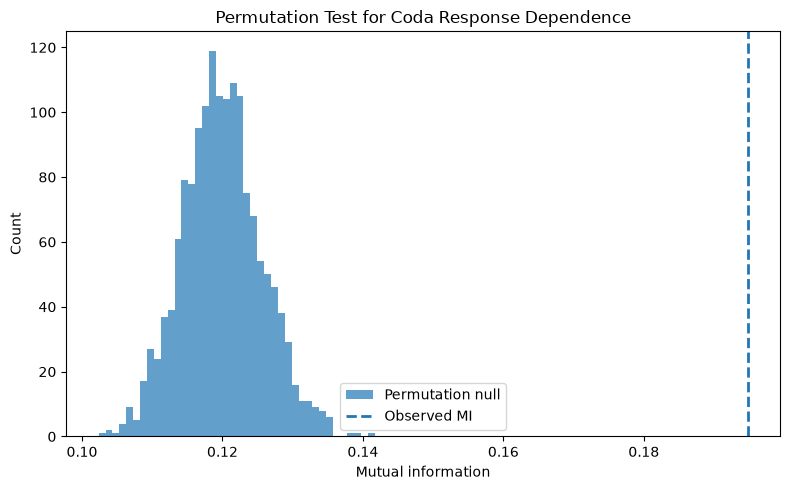

In [51]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    null_mi,
    bins=40,
    alpha=0.7,
    label="Permutation null"
)

ax.axvline(
    observed_mi,
    linestyle="--",
    linewidth=2,
    label="Observed MI"
)

ax.set_xlabel("Mutual information")
ax.set_ylabel("Count")
ax.set_title("Permutation Test for Coda Response Dependence")
ax.legend()

plt.tight_layout()


plt.savefig(
    "figure5_permutation_test.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Transition-Specific Permutation Tests

To identify which individual coda transitions contributed to the overall sequential dependence, permutation tests were performed for all 16 possible previous-type → response-type combinations.

For each transition, the observed count was compared with counts obtained under the same within-AudioFile × responding-Whale permutation procedure.

Because 16 transitions were tested, p-values were corrected using the Benjamini-Hochberg false discovery rate (FDR) procedure.

In [ ]:
transition_results = []

for signal_type in known_types:
    for response_type in known_types:

        observed_count = (
            (
                (signal_response_pairs["prev_type"] == signal_type)
                &
                (signal_response_pairs["assigned_type"] == response_type)
            )
            .sum()
        )

        null_counts = []

        rng = np.random.default_rng(42)

        for _ in range(5000):

            permuted = signal_response_pairs.copy()

            permuted["permuted_response"] = (
                permuted
                .groupby(["AudioFile", "Whale"])["assigned_type"]
                .transform(
                    lambda x: rng.permutation(x.to_numpy())
                )
            )

            permuted_count = (
                (
                    (permuted["prev_type"] == signal_type)
                    &
                    (permuted["permuted_response"] == response_type)
                )
                .sum()
            )

            null_counts.append(permuted_count)

        null_counts = np.array(null_counts)

        p_value = (
            np.sum(null_counts >= observed_count) + 1
        ) / 5001

        null_mean = null_counts.mean()

        enrichment = (
            observed_count / null_mean
            if null_mean > 0
            else np.nan
        )

        transition_results.append({
            "signal": signal_type,
            "response": response_type,
            "observed": observed_count,
            "null_mean": null_mean,
            "enrichment": enrichment,
            "p_value": p_value
        })

transition_results = pd.DataFrame(transition_results)

transition_results

,signal,response,observed,null_mean,enrichment,p_value
0,1+1+3,1+1+3,932,894.9282,1.041424,0.000200
1,1+1+3,2+3,4,3.0590,1.307617,0.281344
2,1+1+3,5R1,41,60.8986,0.673250,1.000000
3,1+1+3,5R2,22,40.1142,0.548434,1.000000
4,2+3,1+1+3,5,4.4382,1.126583,0.516897
5,2+3,2+3,0,0.0000,NaN,1.000000
6,2+3,5R1,0,0.3018,0.000000,1.000000
7,2+3,5R2,0,0.2600,0.000000,1.000000
8,5R1,1+1+3,40,59.6226,0.670887,1.000000
9,5R1,2+3,0,0.5050,0.000000,1.000000


In [ ]:
from statsmodels.stats.multitest import multipletests

transition_results["p_fdr"] = multipletests(
    transition_results["p_value"],
    method="fdr_bh"
)[1]

transition_results[
    [
        "signal",
        "response",
        "observed",
        "null_mean",
        "enrichment",
        "p_value",
        "p_fdr"
    ]
].sort_values("p_fdr").round(4)

,signal,response,observed,null_mean,enrichment,p_value,p_fdr
0,1+1+3,1+1+3,932,894.9282,1.0414,0.0002,0.0006
14,5R2,5R1,13,5.1522,2.5232,0.0002,0.0006
10,5R1,5R1,119,106.6474,1.1158,0.0002,0.0006
11,5R1,5R2,10,2.2250,4.4944,0.0002,0.0006
15,5R2,5R2,17,6.4008,2.6559,0.0002,0.0006
1,1+1+3,2+3,4,3.0590,1.3076,0.2813,0.7502
2,1+1+3,5R1,41,60.8986,0.6733,1.0000,1.0000
3,1+1+3,5R2,22,40.1142,0.5484,1.0000,1.0000
7,2+3,5R2,0,0.2600,0.0000,1.0000,1.0000
6,2+3,5R1,0,0.3018,0.0000,1.0000,1.0000


### Interpretation

After correcting for 16 transition-specific tests using the Benjamini-Hochberg false discovery rate procedure, five transitions remained significantly enriched relative to the within-whale permutation null model.

The strongest effects were concentrated within the 5R coda family. In particular:

- **5R1 → 5R2** occurred approximately **4.49 times** more often than expected under the null model.
- **5R2 → 5R2** occurred approximately **2.66 times** more often than expected.
- **5R2 → 5R1** occurred approximately **2.52 times** more often than expected.
- **5R1 → 5R1** showed a smaller but significant enrichment of approximately **1.12 times**.
- **1+1+3 → 1+1+3** was also statistically significant, but its effect size was small, with an enrichment of approximately **1.04 times**.

These results suggest that the strongest non-random sequential structure is concentrated in exchanges involving 5R-type codas.

Because the permutation test preserves the responding whale's local repertoire within each audio file, these enrichments cannot be explained solely by individual whales preferring particular coda types.

However, these results demonstrate structured sequential association rather than the semantic meaning of the codas.

## 8. Robustness Checks

To test whether the observed sequential patterns depended strongly on the chosen response window, the transition analysis was repeated using maximum response gaps of **3, 5, and 8 seconds**.

The goal was to determine whether the main 5R transition patterns remained qualitatively stable under reasonable changes in the temporal definition of a response.

In [ ]:
def build_pairs_for_window(max_gap):
    return dialogue_events_labeled[
        dialogue_events_labeled["assigned_type"].isin(known_types)
        &
        dialogue_events_labeled["prev_type"].isin(known_types)
        &
        (
            dialogue_events_labeled["Whale"]
            != dialogue_events_labeled["prev_whale"]
        )
        &
        dialogue_events_labeled["response_gap"].between(-2, max_gap)
    ].copy()


window_results = {}

for max_gap in [3, 5, 8]:
    pairs = build_pairs_for_window(max_gap)

    counts = pd.crosstab(
        pairs["prev_type"],
        pairs["assigned_type"]
    ).reindex(
        index=known_types,
        columns=known_types,
        fill_value=0
    )

    probs = counts.div(
        counts.sum(axis=1),
        axis=0
    )

    window_results[max_gap] = {
        "n_pairs": len(pairs),
        "counts": counts,
        "probs": probs
    }

    print(f"\n=== {max_gap}-second window ===")
    print("Number of pairs:", len(pairs))
    display(counts)


=== 3-second window ===
Number of pairs: 1034


assigned_type,1+1+3,2+3,5R1,5R2
prev_type,,,,
1+1+3,838,4,26,22
2+3,4,0,0,0
5R1,25,0,72,7
5R2,18,0,5,13



=== 5-second window ===
Number of pairs: 1224


assigned_type,1+1+3,2+3,5R1,5R2
prev_type,,,,
1+1+3,932,4,41,22
2+3,5,0,0,0
5R1,40,0,119,10
5R2,21,0,13,17



=== 8-second window ===
Number of pairs: 1254


assigned_type,1+1+3,2+3,5R1,5R2
prev_type,,,,
1+1+3,954,6,41,22
2+3,7,0,0,0
5R1,40,0,122,10
5R2,21,0,14,17


In [ ]:
key_5r_transitions = [
    ("5R1", "5R1"),
    ("5R1", "5R2"),
    ("5R2", "5R1"),
    ("5R2", "5R2")
]

robustness_rows = []

for max_gap, result in window_results.items():

    counts = result["counts"]
    probs = result["probs"]

    for signal_type, response_type in key_5r_transitions:

        robustness_rows.append({
            "window_seconds": max_gap,
            "transition": f"{signal_type} → {response_type}",
            "count": counts.loc[signal_type, response_type],
            "row_probability": probs.loc[signal_type, response_type]
        })

window_robustness = pd.DataFrame(robustness_rows)

window_robustness.round(3)

,window_seconds,transition,count,row_probability
0,3,5R1 → 5R1,72,0.692
1,3,5R1 → 5R2,7,0.067
2,3,5R2 → 5R1,5,0.139
3,3,5R2 → 5R2,13,0.361
4,5,5R1 → 5R1,119,0.704
5,5,5R1 → 5R2,10,0.059
6,5,5R2 → 5R1,13,0.255
7,5,5R2 → 5R2,17,0.333
8,8,5R1 → 5R1,122,0.709
9,8,5R1 → 5R2,10,0.058


In [ ]:
file_transition_counts = (
    signal_response_pairs
    .groupby(
        ["AudioFile", "prev_type", "assigned_type"]
    )
    .size()
    .reset_index(name="count")
)

file_summary = []

for signal_type, response_type in key_5r_transitions:

    subset = file_transition_counts[
        (file_transition_counts["prev_type"] == signal_type)
        &
        (file_transition_counts["assigned_type"] == response_type)
    ]

    total = subset["count"].sum()

    file_summary.append({
        "signal": signal_type,
        "response": response_type,
        "total": total,
        "files_with_transition": len(subset),
        "max_in_one_file": (
            subset["count"].max()
            if len(subset) > 0
            else 0
        )
    })

file_summary = pd.DataFrame(file_summary)

file_summary["largest_file_share"] = (
    file_summary["max_in_one_file"]
    /
    file_summary["total"]
)

file_summary.round(3)

,signal,response,total,files_with_transition,max_in_one_file,largest_file_share
0,5R1,5R1,119,11,27,0.227
1,5R1,5R2,10,5,4,0.400
2,5R2,5R1,13,6,4,0.308
3,5R2,5R2,17,6,5,0.294


In [ ]:
signal_response_pairs["whale_pair"] = (
    signal_response_pairs[["prev_whale", "Whale"]]
    .astype(str)
    .apply(
        lambda row: " ↔ ".join(sorted(row)),
        axis=1
    )
)

pair_transition_counts = (
    signal_response_pairs
    .groupby(
        [
            "AudioFile",
            "whale_pair",
            "prev_type",
            "assigned_type"
        ]
    )
    .size()
    .reset_index(name="count")
)

pair_transition_counts.head()

,AudioFile,whale_pair,prev_type,assigned_type,count
0,sw061b001,1 ↔ 2.0,1+1+3,1+1+3,7
1,sw061b001,1 ↔ 2.0,5R2,1+1+3,1
2,sw061b001,1 ↔ 5.0,1+1+3,1+1+3,1
3,sw061b001,1 ↔ 6.0,1+1+3,1+1+3,1
4,sw061b001,1 ↔ 9.0,1+1+3,1+1+3,1


In [ ]:
pair_summary = []

for signal_type, response_type in key_5r_transitions:

    subset = pair_transition_counts[
        (pair_transition_counts["prev_type"] == signal_type)
        &
        (pair_transition_counts["assigned_type"] == response_type)
    ]

    total = subset["count"].sum()

    pair_summary.append({
        "signal": signal_type,
        "response": response_type,
        "total": total,
        "pair_contexts": len(subset),
        "max_in_one_pair_context": (
            subset["count"].max()
            if len(subset) > 0
            else 0
        )
    })

pair_summary = pd.DataFrame(pair_summary)

pair_summary["largest_pair_share"] = (
    pair_summary["max_in_one_pair_context"]
    /
    pair_summary["total"]
)

pair_summary.round(3)

,signal,response,total,pair_contexts,max_in_one_pair_context,largest_pair_share
0,5R1,5R1,119,23,14,0.118
1,5R1,5R2,10,5,4,0.400
2,5R2,5R1,13,7,4,0.308
3,5R2,5R2,17,12,3,0.176


### Robustness Interpretation

The main 5R transition patterns were stable across response windows of 3, 5, and 8 seconds.

The effects were also distributed across multiple audio files and multiple whale-pair contexts rather than being driven by a single recording or a single interacting pair.

The rare 5R1 → 5R2 transition showed greater concentration than the other 5R transitions, so its effect should be interpreted more cautiously despite its strong enrichment relative to the permutation null model.

## 9. Limitations

This study has several important limitations.

First, coda labels in the dialogue dataset were predicted by a classifier rather than provided as ground-truth annotations. A high-confidence threshold and a simple training-range filter were used to reduce uncertain assignments, but some classification error may remain.

Second, the Date + Unit grouping used for cross-validation is a proxy for recording context rather than a guaranteed unique recording-session identifier.

Third, the response analysis focuses only on four selected 5-click coda types. Other coda types may participate in communication patterns that are not captured here.

Fourth, the permutation tests preserve the responding whale's local repertoire within each audio file, but they cannot control for all possible behavioral, social, or environmental factors.

Finally, sequential association does not establish semantic meaning. The observed patterns show that some coda types participate in structured exchanges, but they do not reveal what those codas mean to the whales.

Future work should combine acoustic sequence analysis with behavioral context, social identity, movement data, and environmental information.

## 10. Conclusion

This study examined acoustic and sequential structure in sperm whale coda communication using labeled coda data and dialogue recordings.

The analysis showed that selected 5-click coda types can be distinguished using rhythmic structure and overall tempo. Grouped cross-validation demonstrated that these acoustic categories remained highly distinguishable across recording contexts.

Dialogue analysis also revealed structured temporal turn-taking: transitions between different whales occurred substantially faster than same-speaker continuations.

Most importantly, the type of coda produced in response to another whale was associated with the preceding coda type more strongly than expected from the responding whale's local repertoire alone. This non-random sequential structure was especially concentrated among 5R-type codas and remained visible across multiple response windows, recordings, and whale-pair contexts.

These results do not decode the semantic meaning of sperm whale codas. Instead, they identify reproducible acoustic and sequential patterns that may help guide future research into how sperm whales organize social communication.

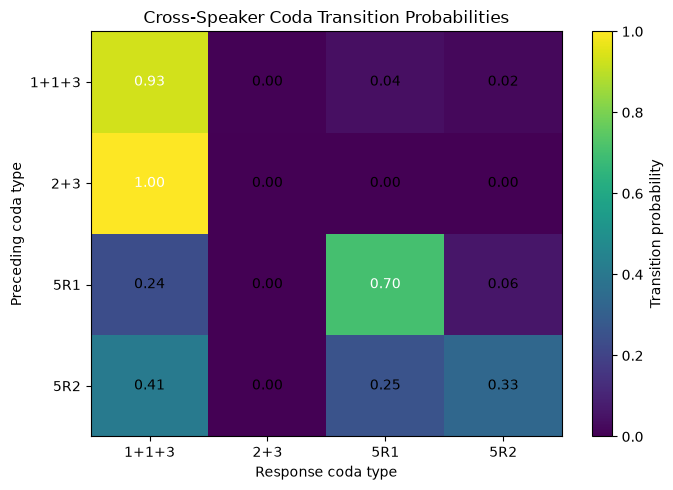

In [52]:
# Cross-speaker transition probability matrix

transition_matrix = (
    transition_probabilities
    .reindex(index=known_types, columns=known_types)
)

fig, ax = plt.subplots(figsize=(7, 5))

im = ax.imshow(
    transition_matrix.values,
    aspect="auto",
    vmin=0,
    vmax=1
)

ax.set_xticks(range(len(known_types)))
ax.set_yticks(range(len(known_types)))

ax.set_xticklabels(known_types)
ax.set_yticklabels(known_types)

ax.set_xlabel("Response coda type")
ax.set_ylabel("Preceding coda type")
ax.set_title("Cross-Speaker Coda Transition Probabilities")

# Add probability values inside cells
for i in range(len(known_types)):
    for j in range(len(known_types)):
        value = transition_matrix.iloc[i, j]
        ax.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center",
            color="white" if value > 0.5 else "black"
        )

fig.colorbar(im, ax=ax, label="Transition probability")

plt.tight_layout()

fig.savefig(
    "figure6_transition_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()